# Yeast Protein Localisation Classifier

Predicting where a protein sits in a yeast cell from eight sequence-derived features, using a tuned and compared set of supervised classifiers.

Experimentally determining protein subcellular localisation is slow and costly, so computational predictors are a useful first pass. This notebook takes 1,464 labelled *Saccharomyces cerevisiae* proteins, trains and tunes five classifiers to predict one of ten compartments, and applies the best model to 20 unlabelled proteins.

**Features** (all continuous scores, roughly 0–1):

| Feature | Meaning |
|---|---|
| `mcg` | McGeoch signal-sequence score (likelihood of a cleavable N-terminal signal peptide) |
| `gvh` | von Heijne signal-peptide score |
| `alm` | ALOM transmembrane-region score |
| `mit` | Mitochondrial targeting signal score |
| `erl` | ER-retention signal (HDEL/KDEL) present |
| `pox` | Peroxisomal targeting signal (e.g. C-terminal SKL) |
| `vac` | Vacuolar targeting score |
| `nuc` | Nuclear localisation signal score |

**Classes:** CYT (cytosol), NUC (nucleus), MIT (mitochondrion), ME1/ME2/ME3 (membrane proteins: no N-terminal signal / uncleaved signal / cleaved signal), EXC (extracellular), VAC (vacuole), POX (peroxisome), ERL (ER lumen).

## 1. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb


from sklearn.model_selection import (
    train_test_split, 
    StratifiedKFold, 
    GridSearchCV, 
)
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, 
    f1_score,
    precision_score,
    recall_score,

)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')

In [2]:
RANDOM_STATE = 7
np.random.seed(RANDOM_STATE)

## 2. Data loading and validation

In [3]:
#load dataset 
df_labelled = pd.read_csv("../data/yeast-labelled.csv")
df_unlabelled = pd.read_csv("../data/yeast-unlabelled.csv")

print('Data reading complete')
display(df_labelled.head())
display(df_unlabelled.head())

FEATURES = list(df_labelled)[:-1] 
LABELS = df_labelled["site"].unique() 

Data reading complete


,mcg,gvh,alm,mit,erl,pox,vac,nuc,site
0,0.42,0.42,0.42,0.20,0.5,0.0,0.49,0.22,ME3
1,0.50,0.44,0.57,0.28,0.5,0.0,0.57,0.22,CYT
2,0.28,0.18,0.72,0.26,0.5,0.0,0.49,0.25,MIT
3,1.00,0.80,0.29,0.36,0.5,0.0,0.52,0.22,ME1
4,0.70,0.65,0.54,0.28,0.5,0.0,0.60,0.40,VAC


,mcg,gvh,alm,mit,erl,pox,vac,nuc
0,0.32,0.45,0.39,0.14,0.5,0.0,0.45,0.22
1,0.35,0.66,0.49,0.21,0.5,0.0,0.54,0.25
2,0.48,0.43,0.51,0.32,0.5,0.0,0.52,0.43
3,0.57,0.60,0.54,0.17,0.5,0.0,0.52,0.22
4,0.44,0.41,0.44,0.13,0.5,0.0,0.49,0.42


In [4]:
#Validation + checks 

print(df_labelled.isnull().sum(),'\n')
print('Number of samples:',len(df_labelled),'\n')
print(df_labelled.dtypes,'\n')
print(df_labelled.nunique()) 

mcg     0
gvh     0
alm     0
mit     0
erl     0
pox     0
vac     0
nuc     0
site    0
dtype: int64 

Number of samples: 1464 

mcg     float64
gvh     float64
alm     float64
mit     float64
erl     float64
pox     float64
vac     float64
nuc     float64
site     object
dtype: object 

mcg     80
gvh     79
alm     53
mit     78
erl      2
pox      3
vac     48
nuc     68
site    10
dtype: int64


- 1,464 labelled proteins, no missing values, and every feature is `float64`.
- `erl` and `pox` take only 2 and 3 distinct values, so they behave as discrete markers rather than continuous scores.
- `site` is the target: a 10-class label.

In [5]:
#Encoding Y values to ensure compatibility with models 

X =  df_labelled[FEATURES]
Y = df_labelled['site']

le = LabelEncoder()
y_encoded = le.fit_transform(Y)
class_labels = le.classes_
print(y_encoded)
print('Mapping check',le.classes_) #checked with dflab head, matches up, use inverse transform later following predictions to convert back to string labels 

class_counts = Y.value_counts().sort_index()

[5 0 6 ... 5 8 6]
Mapping check ['CYT' 'ERL' 'EXC' 'ME1' 'ME2' 'ME3' 'MIT' 'NUC' 'POX' 'VAC']


In [6]:
#consistent colour palette for clearer representations
sites_sorted = sorted(LABELS)
husl_palette = sb.color_palette("bright", len(sites_sorted))
colour_dictionary = dict(zip(sites_sorted, husl_palette))

### Class distribution
How many proteins belong to each compartment. A strongly imbalanced target changes how the data should be split and how models should be scored.

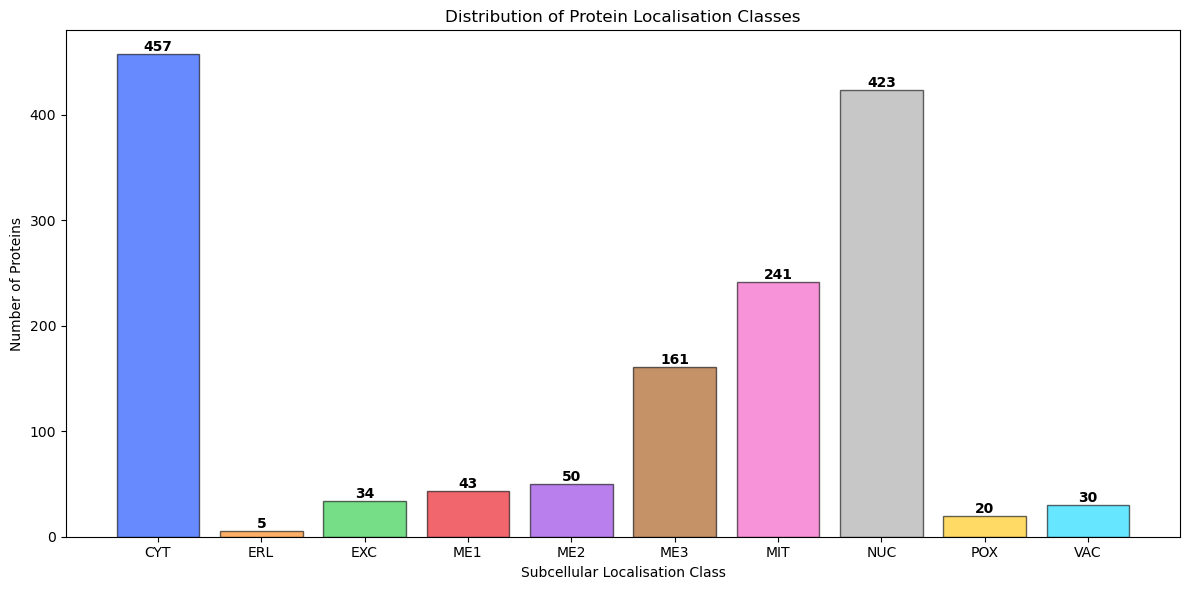

In [7]:
#class frequency distribution
fig, ax = plt.subplots(figsize=(12, 6))
colors = sb.color_palette("bright", len(class_counts))

bars = ax.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', alpha = 0.6)
ax.set_xlabel('Subcellular Localisation Class')
ax.set_ylabel('Number of Proteins')
ax.set_title('Distribution of Protein Localisation Classes')
for bar, count in zip(bars, class_counts.values):
    ax.annotate(f'{count}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

- CYT (457) and NUC (423) make up 60% of the data, while ERL has only 5 proteins and POX 20.
- Accuracy alone would reward a model that ignores rare compartments. This motivates:
  - a **stratified** train/test split
  - **macro-F1** (every class weighted equally) as the tuning metric
  - `class_weight='balanced'` where the model supports it

### Train/test split
An 80:20 stratified split keeps each class's proportion the same in both sets. All further exploration uses the training set only, so the test set gives an unbiased estimate of performance on unseen proteins.

In [8]:
# train-test split 
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, random_state=RANDOM_STATE, test_size=0.2, stratify=y_encoded) #even class proportions due to the nature of imbalance 

## 3. Exploratory analysis (training set only)

In [9]:
#ERL and POX unique values
print('Feature: erl unique values',X_train['erl'].unique())
print('Feature: pox unique values',X_train['pox'].unique())

Feature: erl unique values [0.5 1. ]
Feature: pox unique values [0.   0.83 0.5 ]


### Pairwise feature relationships
A pairplot coloured by compartment shows which features (or feature pairs) separate classes and which features move together.

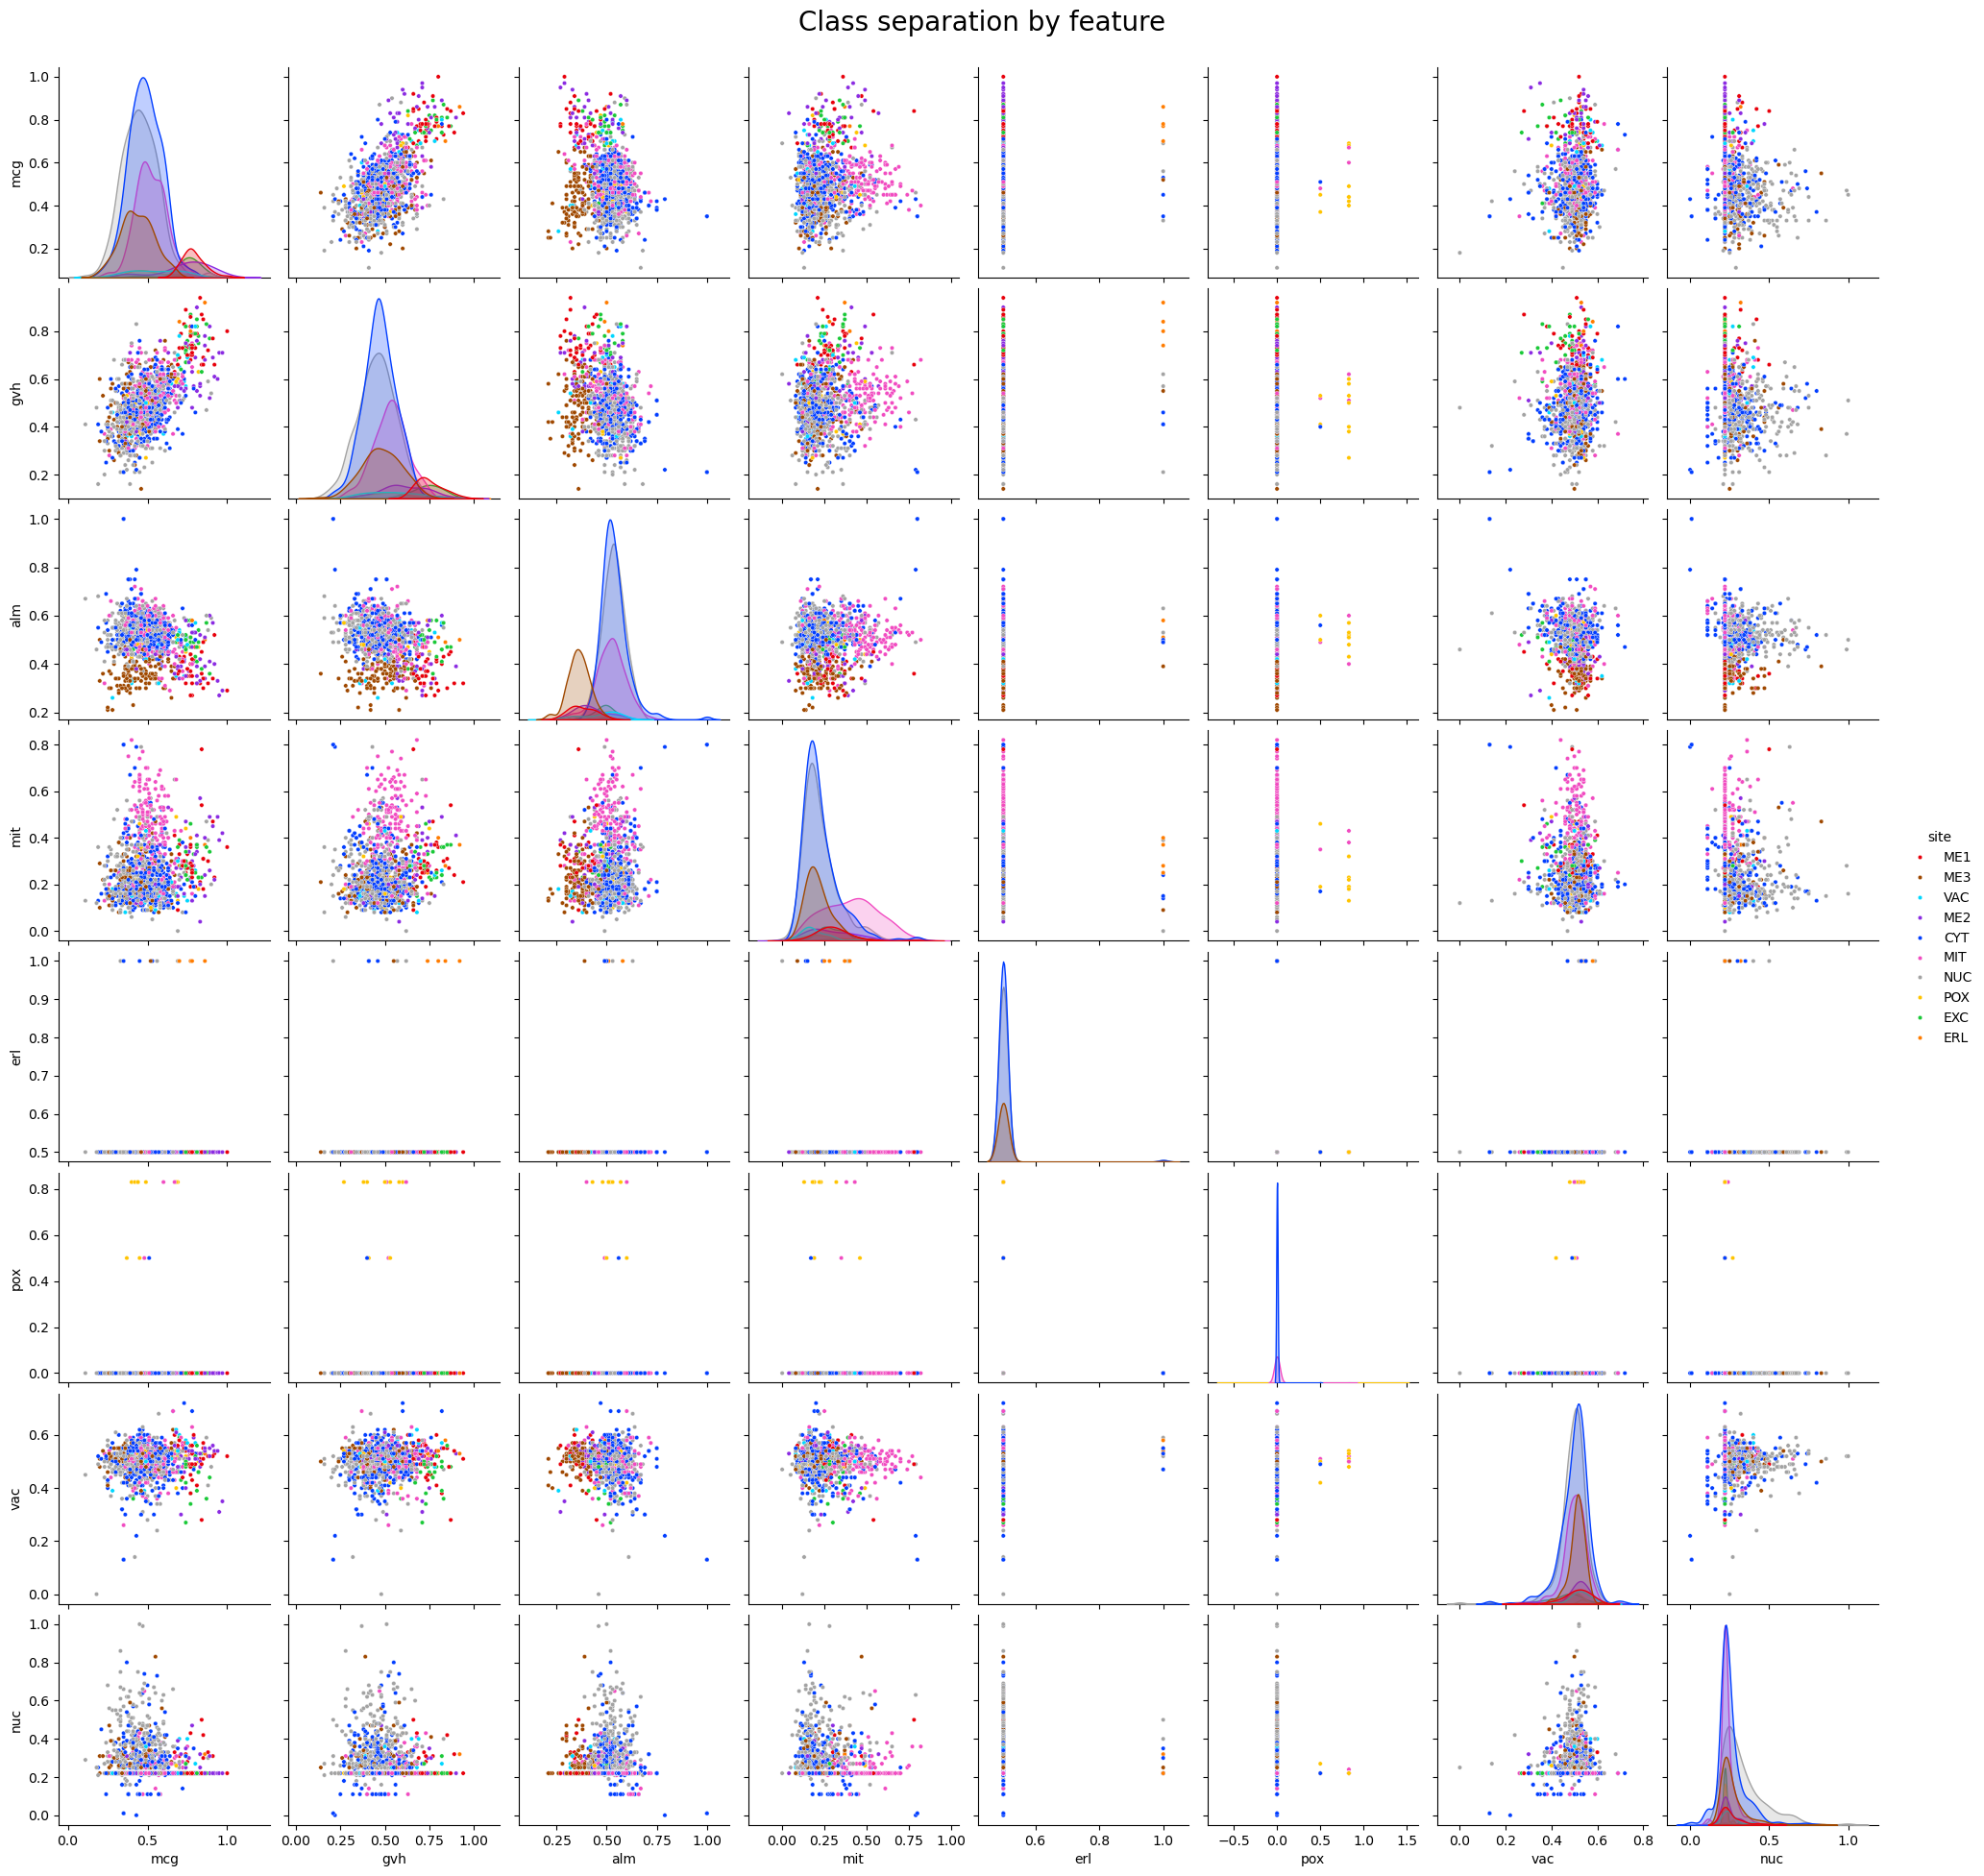

None

In [10]:
#seaborn pairplot by feature

train_df = pd.DataFrame(X_train)
train_df['site'] = y_train

plot_df = train_df.copy()
plot_df['site']= le.inverse_transform(train_df['site'])

plot = sb.pairplot(plot_df, hue = 'site', palette= colour_dictionary,plot_kws ={'s':10, 'alpha':1})
plot.figure.subplots_adjust(top=0.95)
plot.figure.suptitle("Class separation by feature",fontsize = 20)

display(plt.show())

- `erl` cleanly flags ERL proteins, and non-zero `pox` almost exclusively marks POX proteins. Both should be high-precision signals for these rare classes.
- `mcg` and `gvh` show a clear positive association, which is investigated below.
- Most other classes overlap heavily in every 2D projection, so no single pair of features separates them.

### Summary statistics
Ranges and spread of each feature in the training set, used to check scale and to choose a scaler.

In [11]:
X_train.describe()

,mcg,gvh,alm,mit,erl,pox,vac,nuc
count,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000,1171.000000
mean,0.501785,0.499522,0.501580,0.260017,0.504697,0.008087,0.499231,0.275602
std,0.137449,0.122910,0.088777,0.134370,0.048253,0.078029,0.058987,0.105193
min,0.110000,0.140000,0.210000,0.000000,0.500000,0.000000,0.000000,0.000000
25%,0.410000,0.420000,0.460000,0.170000,0.500000,0.000000,0.480000,0.220000
50%,0.490000,0.490000,0.510000,0.220000,0.500000,0.000000,0.510000,0.220000
75%,0.580000,0.570000,0.560000,0.320000,0.500000,0.000000,0.530000,0.300000
max,1.000000,0.940000,1.000000,0.820000,1.000000,0.830000,0.720000,1.000000


- All features already lie within 0–1.
- `erl` sits at 0.5 and `pox` at 0 for at least 75% of proteins, confirming they are sparse markers.
- `mit` and `nuc` have low medians (0.22) but maxima near 0.8–1.0, which indicates long right tails.

### Feature distributions by class
Per-class boxplots show which features shift between compartments, and therefore which carry discriminative signal.

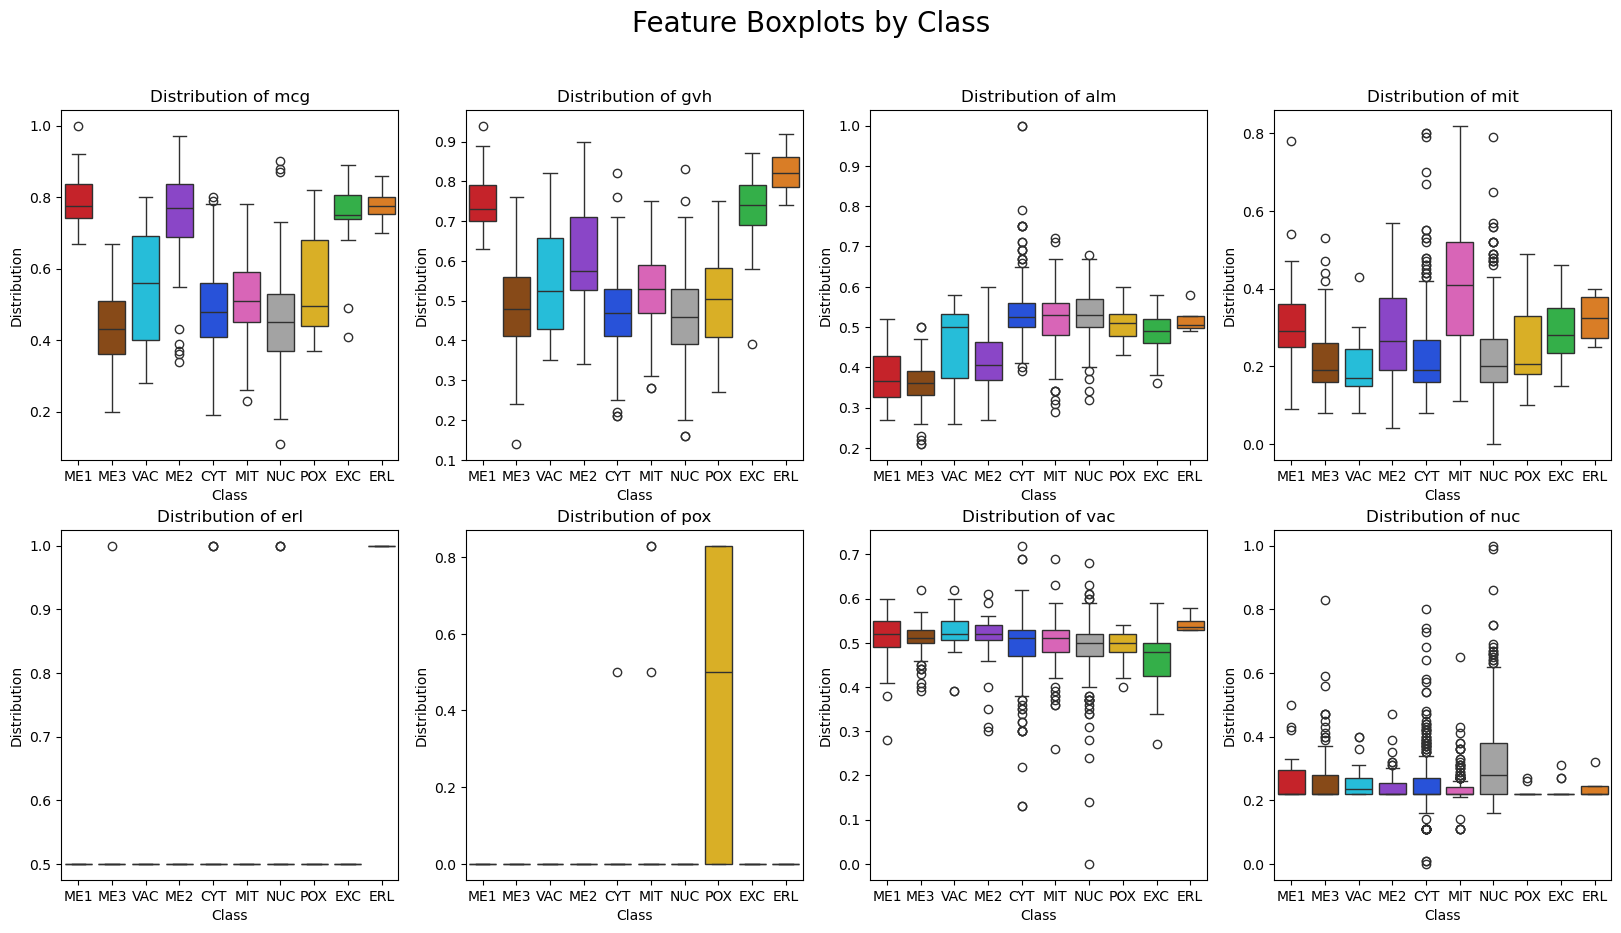

In [12]:
#boxplots to investigate each feature by class

fig,ax = plt.subplots(2,4, figsize=(20,10))
ax = ax.flatten() #flattened into 0-7 list, don't need to refer by matrix position

for i,colname in enumerate(FEATURES): 
    sb.boxplot(x="site", y=colname, data=plot_df, ax=ax[i], palette=colour_dictionary, hue = 'site',legend=False, saturation=0.7)
    ax[i].set_title(f'Distribution of {colname}')
    ax[i].set_xlabel('Class')
    ax[i].set_ylabel('Distribution')

plt.suptitle('Feature Boxplots by Class',fontsize = 20,)
plt.show()


- **CYT and NUC overlap on almost every feature.** This is the main expected source of error.
- ME1 stands out with high `mcg`/`gvh`, ME1 and ME3 have low `alm`, and MIT has the highest `mit` scores, so these classes should be easier to separate.
- `vac` and `nuc` are noisy, with many outliers and little shift between classes.

### Feature shape and choice of scaler
Histograms show the shape of each feature's distribution, which informs how features should be scaled.

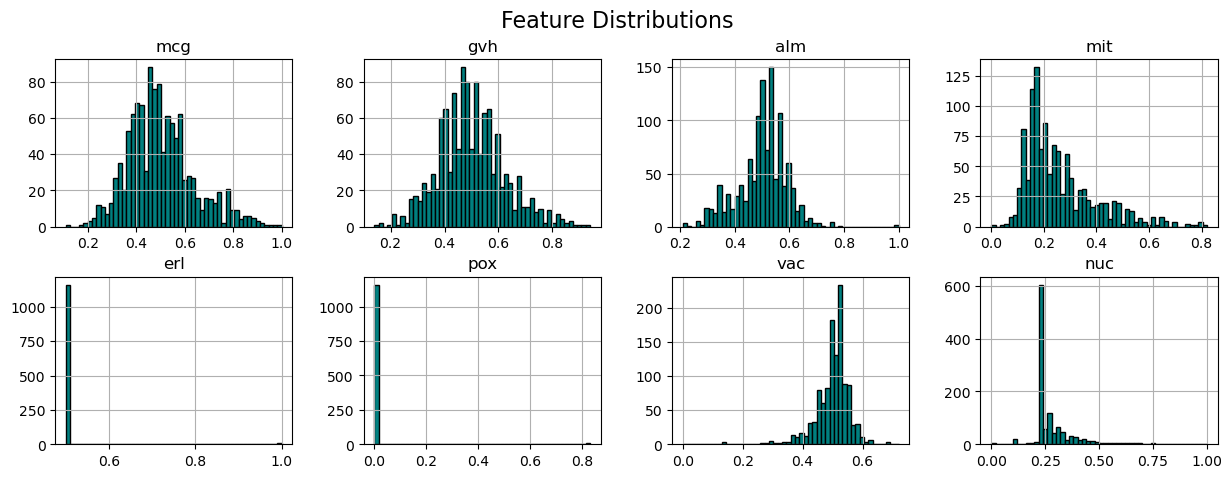

In [13]:
#feature distibution
X_train.hist(bins=50, figsize=(15, 5), color='teal', edgecolor='black', layout = (2,4))
plt.suptitle("Feature Distributions", fontsize=16)
plt.show()

- `mcg`, `gvh` and `alm` are roughly Gaussian, `mit`, `vac` and `nuc` are skewed, and `erl`/`pox` are single spikes.
- Because the features are already bounded on a shared 0–1 scale, `MinMaxScaler` was used. It is a simple linear rescale that preserves each feature's shape and skew.

### Feature dependencies
Pearson (linear) and Spearman (monotonic) correlations check whether any features are redundant before modelling.

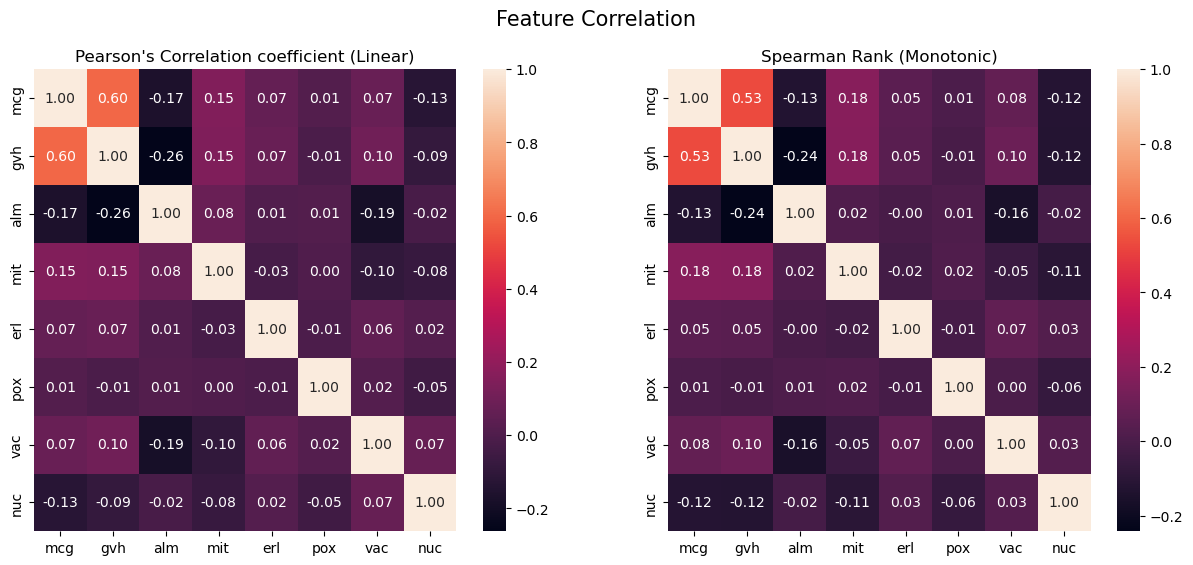

None

In [14]:
fig,ax = plt.subplots(1,2, figsize=(15,6))
ax = ax.flatten()

correlation_p = X_train.corr(method="pearson")
sb.heatmap(correlation_p,annot=True,fmt=".2f",ax=ax[0]).set(title= "Pearson's Correlation coefficient (Linear)") 
correlation_sp = X_train.corr(method="spearman") #correlation is a data frame 
sb.heatmap(correlation_sp,annot=True,fmt=".2f",ax=ax[1]).set(title= "Spearman Rank (Monotonic)") #rank correlations (monotonic relationships)

plt.suptitle("Feature Correlation",fontsize = 15)
display(plt.show())

- `mcg` and `gvh` correlate moderately (Pearson r = 0.60, Spearman ρ = 0.53). This makes biological sense, since both score N-terminal signal peptides.
- The correlation is not strong enough to treat either feature as redundant, so both were kept.
- All other pairs are weak (|r| ≤ 0.26).

## 4. Model training and hyperparameter tuning

Five classifiers spanning linear, kernel, tree-ensemble and neural approaches:

| Model | Approach | Tuned hyperparameters |
|---|---|---|
| Logistic Regression | Linear model with class probabilities (one-vs-rest via `liblinear`) | `C`, penalty (L1/L2) |
| SVC | Maximum-margin decision boundary, optionally via a kernel | `C`, `gamma`, kernel (linear/RBF/poly) |
| Random Forest | Majority vote over trees built on bootstrapped samples and random feature subsets | `n_estimators`, `max_depth`, `min_samples_leaf` |
| Gradient Boosted Trees | Sequential shallow trees, each correcting the previous ones' errors | `n_estimators`, `max_depth`, `learning_rate` |
| MLP | Feed-forward neural network | hidden layers, `alpha` (L2), `learning_rate_init`, `max_iter` |

**Fitting strategy**
- Each model is wrapped in a `Pipeline` (`MinMaxScaler` followed by the classifier), so scaling is fit only on each training fold and nothing leaks. Tree models don't need scaling, but it is applied to all models for a consistent pipeline.
- `GridSearchCV` with **5-fold stratified CV** tests every hyperparameter combination.
- Combinations are ranked by **macro-F1**, not accuracy or weighted-F1. Correctly identifying rare compartments matters as much scientifically as identifying CYT/NUC. This trades a little overall accuracy for less bias towards the majority classes.

In [15]:

CV = StratifiedKFold(n_splits = 5, shuffle=True, random_state=RANDOM_STATE) 

model_configs = {
    'SVC': {
        'model': SVC(class_weight='balanced'), #balanced due to the underrepresentation of ERL etc. 
        'grid': {'clf__C': [1, 10, 100], 'clf__gamma': ['scale', 'auto'],'clf__kernel': ['linear','rbf', 'poly']}
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'), #max features set to auto naturally = automatic feature selection (?)
        'grid': {'clf__n_estimators': [200,300,500], 'clf__max_depth': [None, 10, 20,30],'clf__min_samples_leaf':[2,3,5]} #small, overfitting possible but need to detect rare classes 
    },
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, class_weight='balanced',solver='liblinear'),
        'grid': {'clf__C': [0.01,0.1, 1, 10,100],'clf__penalty': ['l2', 'l1']}
    },
     'Gradient Boosted Trees':{
         'model': GradientBoostingClassifier(random_state=RANDOM_STATE),
         'grid':{'clf__n_estimators':[100, 200, 300], 'clf__max_depth':[3, 5, 7], 'clf__learning_rate': [0.01, 0.05, 0.1]}
     },
     'Multi-layer Perceptron': {
         'model':MLPClassifier(random_state=RANDOM_STATE, early_stopping=True, validation_fraction=0.1, verbose=False),
         'grid':{'clf__hidden_layer_sizes':[(50,), (100,), (50, 50), (100, 50)],'clf__alpha': [ 0.001, 0.01,0.1],'clf__max_iter': [500,1000],'clf__learning_rate_init': [ 0.005,0.01,0.02]}
     } #default softmax, don't need to specify 
}

results = {}

for name, configuration in (model_configs.items()):
    print('Performing hyperparameter optimisation for',name)
    
    #set up the pipeline

    pipe = Pipeline([
         ('scaler', MinMaxScaler()),
         ('clf', configuration['model'])
     ])
    
    grid = GridSearchCV(pipe, configuration['grid'], cv=CV, scoring='f1_macro', n_jobs=-1, verbose=0, refit = True) #finds the best parameters, and refits model on the entire data 
    grid.fit(X_train, y_train) 

    print(f"Best parameters: {grid.best_params_}")
    print(f"Best CV F1 score: {grid.best_score_:.4f}")

    results[name] = {
        'model': grid.best_estimator_, #scoring the classifier and associated pipeline 
        'best_params': grid.best_params_,
        'cv_score': grid.best_score_
    }


Performing hyperparameter optimisation for SVC
Best parameters: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
Best CV F1 score: 0.5399
Performing hyperparameter optimisation for Random Forest
Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}
Best CV F1 score: 0.5904
Performing hyperparameter optimisation for Logistic Regression
Best parameters: {'clf__C': 1, 'clf__penalty': 'l2'}
Best CV F1 score: 0.5128
Performing hyperparameter optimisation for Gradient Boosted Trees
Best parameters: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}
Best CV F1 score: 0.5131
Performing hyperparameter optimisation for Multi-layer Perceptron
Best parameters: {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (100, 50), 'clf__learning_rate_init': 0.02, 'clf__max_iter': 500}
Best CV F1 score: 0.5213


| Model | Best hyperparameters | CV macro-F1 |
|---|---|---|
| Random Forest | `max_depth=None`, `min_samples_leaf=2`, `n_estimators=200` | **0.590** |
| SVC | `C=1`, `gamma='scale'`, `kernel='rbf'` | 0.540 |
| MLP | `alpha=0.01`, `hidden_layer_sizes=(100, 50)`, `learning_rate_init=0.02`, `max_iter=500` | 0.521 |
| Gradient Boosted Trees | `learning_rate=0.05`, `max_depth=3`, `n_estimators=100` | 0.513 |
| Logistic Regression | `C=1`, `penalty='l2'` | 0.513 |

- Random Forest has the highest CV macro-F1, 0.05 ahead of SVC (see the fold-level comparison below).
- The non-linear RBF kernel beat linear and polynomial kernels for SVC, which suggests class boundaries are not linear in feature space.
- GBT and MLP have no `class_weight` option, which likely contributes to their lower macro-F1.

### Is the Random Forest vs SVC gap meaningful?
Cross-validation (CV) favours Random Forest (0.590 vs 0.540 macro-F1), but on the held-out test set the two score the same (0.595, see section 5). The table below puts both views together. The CV columns come from the same 5 stratified folds used in the grid search, and their spread shows how much of the 0.05 CV gap could just be fold-to-fold noise.

In [16]:
from sklearn.model_selection import cross_val_score

cv_spread = []
for name in ['Random Forest', 'SVC']:
    # best pipeline re-scored on the same stratified folds used by GridSearchCV
    fold_scores = cross_val_score(results[name]['model'], X_train, y_train,
                                  cv=CV, scoring='f1_macro', n_jobs=-1)
    row = {'Model': name,
           'CV mean': fold_scores.mean(), 'CV std': fold_scores.std(),
           'CV min': fold_scores.min(), 'CV max': fold_scores.max(),
           'Test macro-F1': f1_score(y_test, results[name]['model'].predict(X_test), average='macro')}
    row.update({f'Fold {i+1}': s for i, s in enumerate(fold_scores)})
    cv_spread.append(row)

cv_spread_df = pd.DataFrame(cv_spread).set_index('Model')
display(cv_spread_df.round(3))

,CV mean,CV std,CV min,CV max,Test macro-F1,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Model,,,,,,,,,,
Random Forest,0.59,0.049,0.512,0.666,0.595,0.588,0.512,0.666,0.593,0.593
SVC,0.54,0.021,0.513,0.561,0.595,0.513,0.556,0.561,0.516,0.554


- Random Forest averages 0.590 ± 0.049 and SVC 0.540 ± 0.021 (mean ± std over 5 folds). The 0.05 gap is about one Random Forest standard deviation, so it is suggestive rather than decisive.
- Random Forest wins 4 of the 5 folds, but it is also the less stable model: its folds range from 0.512 to 0.666, versus 0.513 to 0.561 for SVC. Its worst fold is no better than SVC's worst.

## 5. Test-set evaluation
`GridSearchCV` refits each tuned pipeline on the full training set. Each model is then scored once on the held-out 20% test set.

In [17]:
evaluation_results = []

for name, result in results.items():
    model = result['model']  # This is now a Pipeline with scaler included
    y_pred = model.predict(X_test)  # Raw data - pipeline handles scaling
    y_pred_proba = model.predict_proba(X_test) if hasattr(model, 'predict_proba') else None #modil confidence 
    
    acc = accuracy_score(y_test, y_pred)
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    f1_macro = f1_score(y_test, y_pred, average='macro')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    
    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'F1 (Weighted)': f1_weighted,
        'F1 (Macro)': f1_macro,
        'Precision': precision,
        'Recall': recall,
        'CV Score': result['cv_score']
    })
    
    results[name]['test_accuracy'] = acc
    results[name]['test_f1_macro'] = f1_macro
    results[name]['test_f1_weighted'] = f1_weighted
    results[name]['y_pred'] = y_pred
    results[name]['y_pred_proba'] = y_pred_proba
    
    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.3f}")
    print(f"  F1 (Weighted): {f1_weighted:.3f}")
    print(f"  F1 (Macro): {f1_macro:.3f}")

# Create summary DataFrame
eval_df = pd.DataFrame(evaluation_results)
eval_df = eval_df.sort_values('F1 (Weighted)', ascending=False)
print("\n Evaluation results:")
print(eval_df.to_string(index=False))


SVC:
  Accuracy: 0.573
  F1 (Weighted): 0.567
  F1 (Macro): 0.595

Random Forest:
  Accuracy: 0.594
  F1 (Weighted): 0.583
  F1 (Macro): 0.595

Logistic Regression:
  Accuracy: 0.573
  F1 (Weighted): 0.571
  F1 (Macro): 0.531

Gradient Boosted Trees:
  Accuracy: 0.614
  F1 (Weighted): 0.602
  F1 (Macro): 0.583

Multi-layer Perceptron:
  Accuracy: 0.580
  F1 (Weighted): 0.567
  F1 (Macro): 0.492

 Evaluation results:
                 Model  Accuracy  F1 (Weighted)  F1 (Macro)  Precision   Recall  CV Score
Gradient Boosted Trees  0.614334       0.602312    0.583380   0.605971 0.614334  0.513138
         Random Forest  0.593857       0.583339    0.595104   0.585247 0.593857  0.590409
   Logistic Regression  0.573379       0.571181    0.531037   0.586608 0.573379  0.512815
Multi-layer Perceptron  0.580205       0.567440    0.492266   0.569958 0.580205  0.521299
                   SVC  0.573379       0.566525    0.595450   0.582181 0.573379  0.539867


### Performance comparison visualisation
Comparing accuracy, weighted-F1 and macro-F1 side by side shows whether a model's overall score is coming at the expense of rare classes.

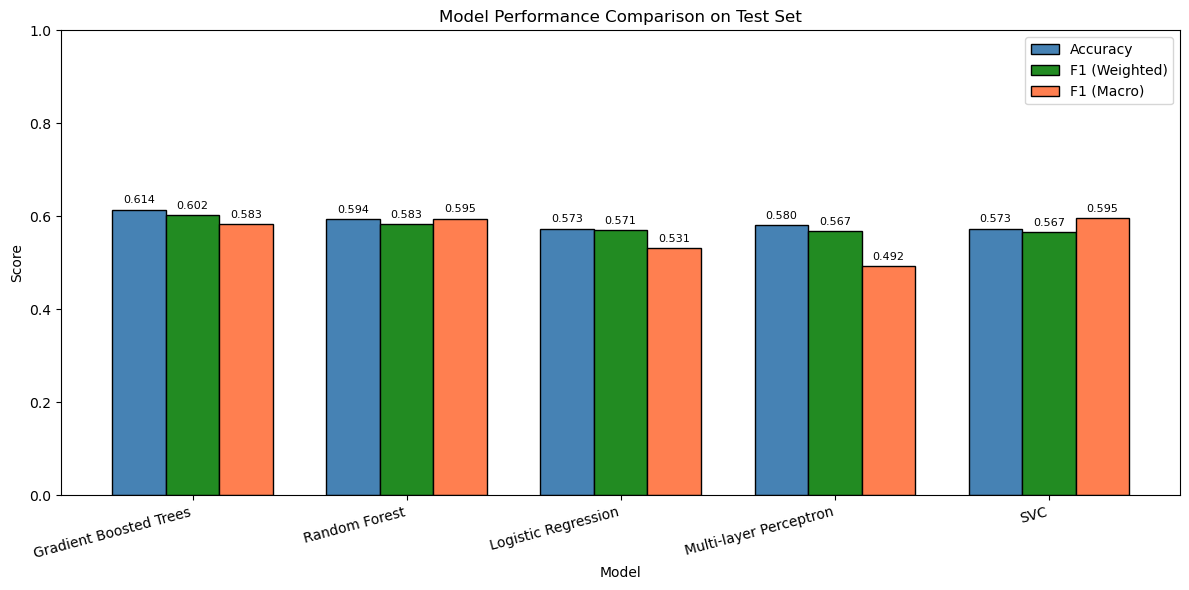

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(eval_df))
width = 0.25

bars1 = ax.bar(x - width, eval_df['Accuracy'], width, label='Accuracy', color='steelblue', edgecolor='black' )
bars2 = ax.bar(x, eval_df['F1 (Weighted)'], width, label='F1 (Weighted)', color='forestgreen', edgecolor='black')
bars3 = ax.bar(x + width, eval_df['F1 (Macro)'], width, label='F1 (Macro)', color='coral', edgecolor='black')

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison on Test Set')
ax.set_xticks(x)
ax.set_xticklabels(eval_df['Model'], rotation=15, ha='right')
ax.legend()
ax.set_ylim(0, 1.0)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

- **Random Forest and SVC tie for the best macro-F1 (0.595).**
- Random Forest's CV advantage did not carry over to unseen data.
- With only ~1,170 training proteins and a handful of samples in the rare classes, a single fold can swing macro-F1 by several points. This is why the test-set tie (0.595 each) should not be over-interpreted.
- Random Forest is still the better choice,
- GBT has the highest accuracy (0.614) and weighted-F1 (0.602), but a lower macro-F1. It does well on large classes and less well on rare ones.
- MLP's accuracy (0.580) is competitive, but it has the lowest macro-F1 (0.492). Its headline accuracy hides weak minority-class performance, and Logistic Regression (0.531) shows the same pattern.

### Per-class errors
Confusion matrices show which compartments get mistaken for each other, which the aggregate scores above can't reveal.

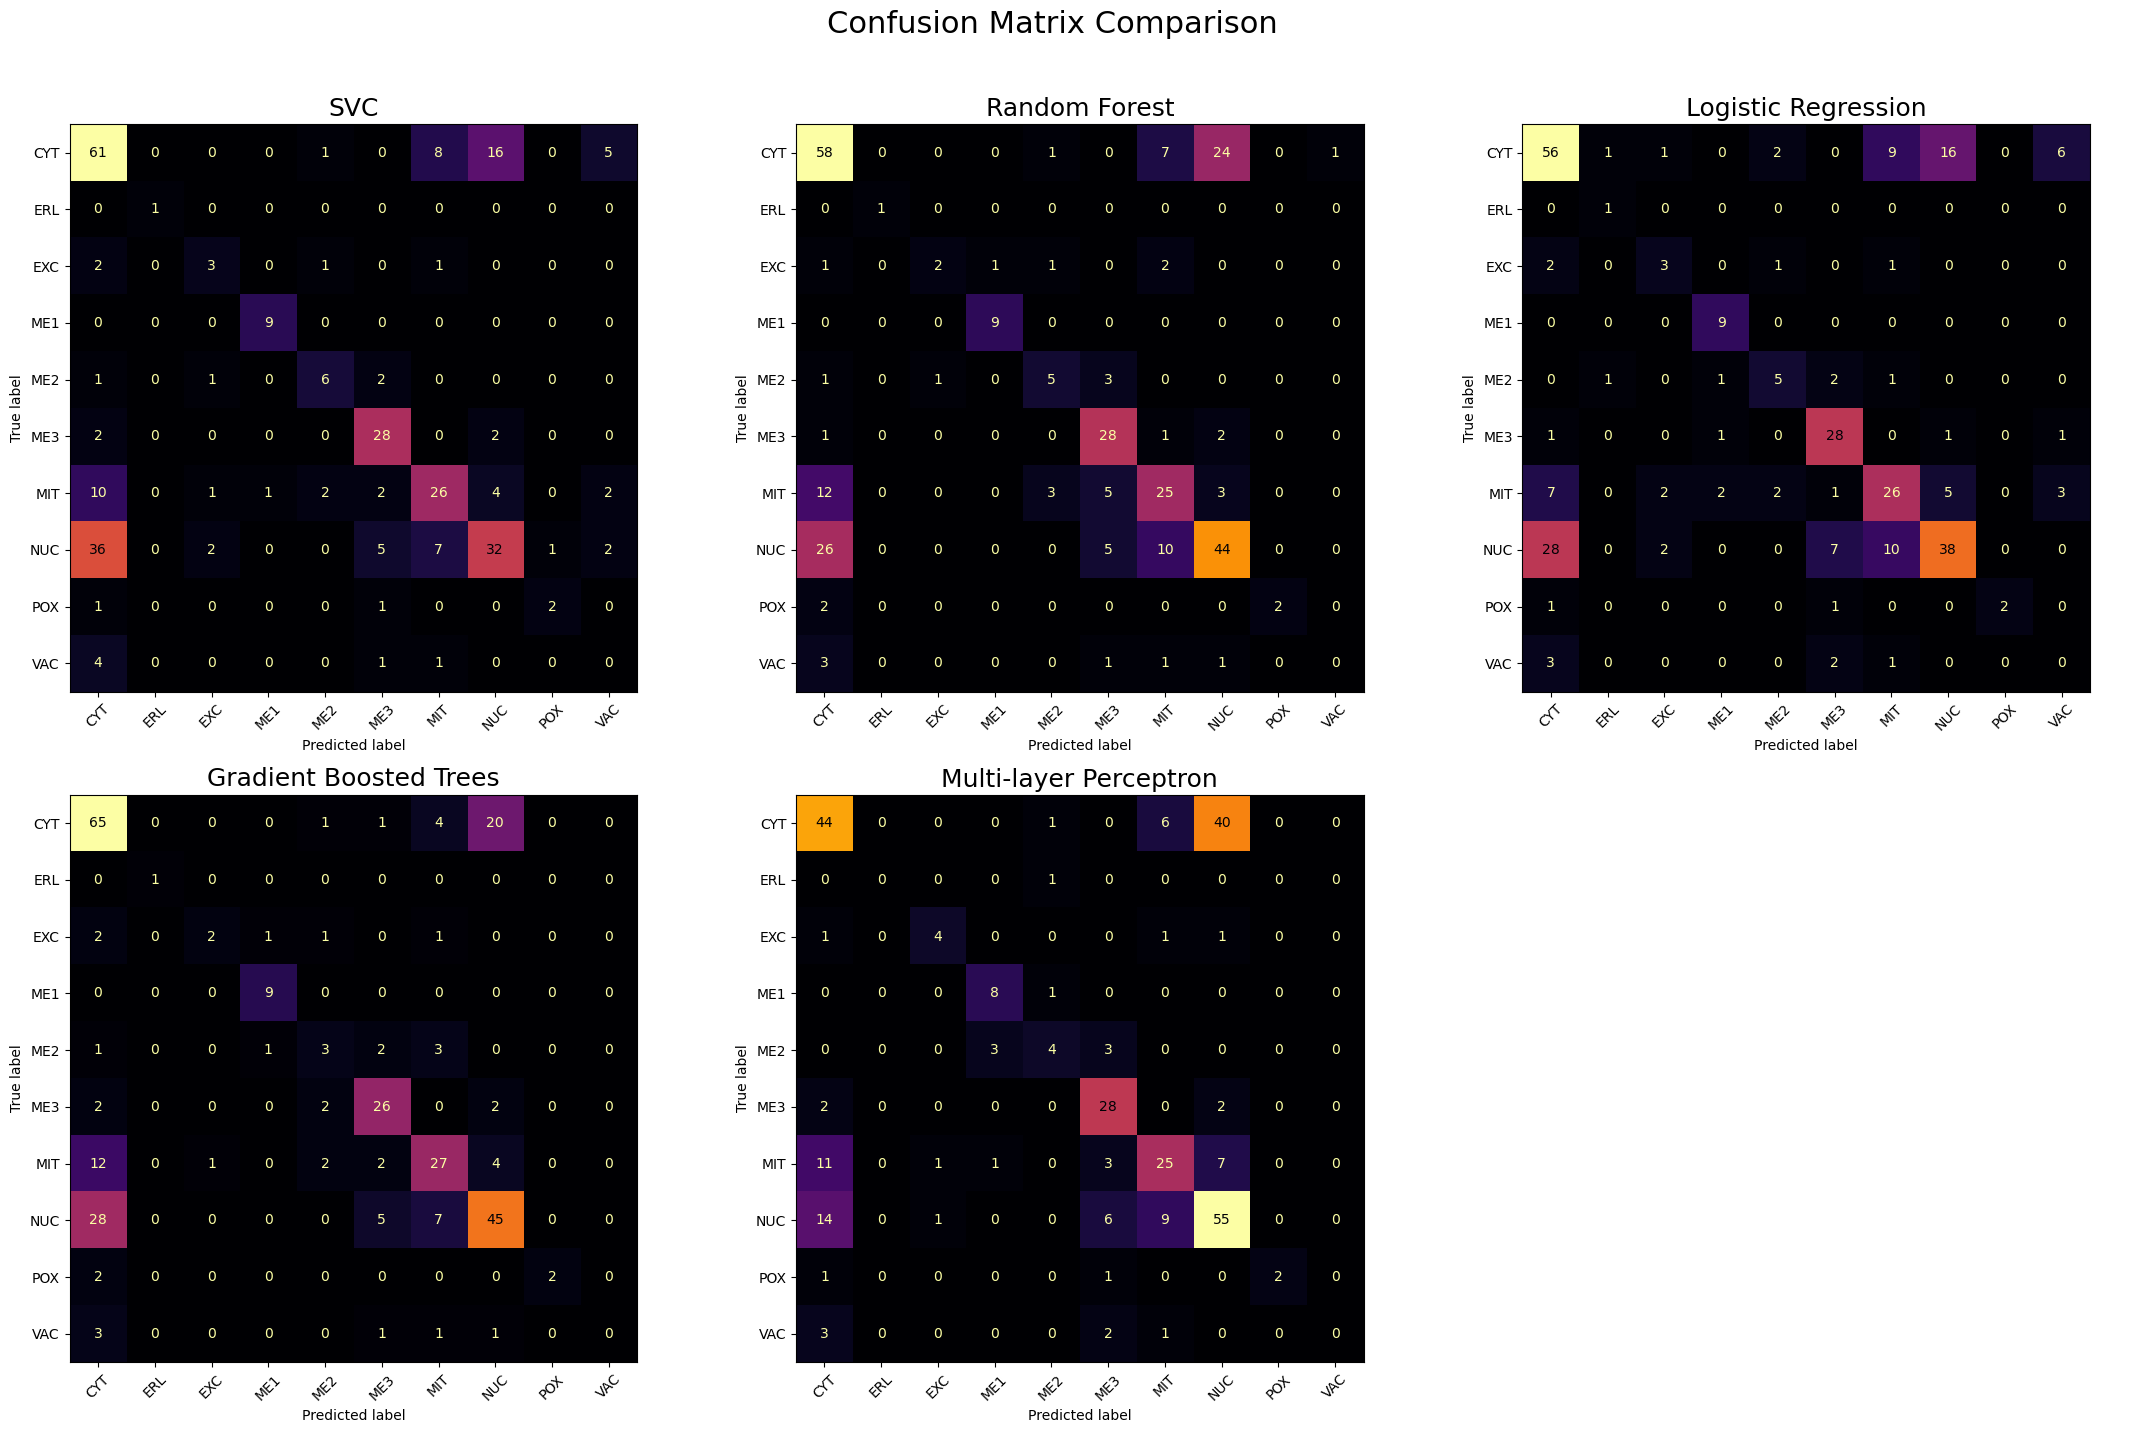


--- Final Performance Reports ---
SVC
              precision    recall  f1-score   support

         CYT       0.52      0.67      0.59        91
         ERL       1.00      1.00      1.00         1
         EXC       0.43      0.43      0.43         7
         ME1       0.90      1.00      0.95         9
         ME2       0.60      0.60      0.60        10
         ME3       0.72      0.88      0.79        32
         MIT       0.60      0.54      0.57        48
         NUC       0.59      0.38      0.46        85
         POX       0.67      0.50      0.57         4
         VAC       0.00      0.00      0.00         6

    accuracy                           0.57       293
   macro avg       0.60      0.60      0.60       293
weighted avg       0.58      0.57      0.57       293

Random Forest
              precision    recall  f1-score   support

         CYT       0.56      0.64      0.59        91
         ERL       1.00      1.00      1.00         1
         EXC       0.67  

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(22, 14))
axes = axes.flatten()

for i, (name, result) in enumerate(results.items()):
    cmd = ConfusionMatrixDisplay.from_predictions(
        y_test, 
        result['y_pred'], 
        display_labels=class_labels, 
        ax=axes[i],   
        cmap='inferno',  
        xticks_rotation=45, 
        colorbar=False      
    )
    axes[i].set_title((name), fontsize=18)



axes[-1].axis('off')

plt.suptitle('Confusion Matrix Comparison', fontsize=22, y = 1.02)
plt.tight_layout()
plt.show()

print("\n--- Final Performance Reports ---")
for name, result in results.items():
    print(name)
    print(classification_report(y_test, result['y_pred'], target_names=class_labels))

- **CYT ↔ NUC is the dominant error** in every model (e.g. Random Forest: 24 CYT predicted as NUC, 26 NUC as CYT). This matches the overlap seen in the boxplots.
- ME1 (9/9 for most models) and ME3 (~28/32) are classified well despite being minority classes, which suggests distinctive feature profiles.
- The single ERL test protein is correctly identified by every model except the MLP, consistent with the MLP's poor sensitivity to rare classes.
- VAC is never correctly predicted by any model (0/6 test proteins), and EXC and POX are only partially recovered.
- However, the dataset has only 6 VAC and 1 ERL proteins for testing, so per-class scores for those are very unreliable.

## 6. Model selection
**Random Forest** is taken forward. It ties for the best test macro-F1 (0.595) and stays competitive on accuracy (0.594) and weighted-F1 (0.583). It also had the highest CV macro-F1 (0.590), so its test performance is consistent with cross-validation rather than a lucky split.

In [20]:
#choose the best model 

best_model_name = 'Random Forest'
best_model = results[best_model_name]['model']

## 7. Feature importance
Two complementary views of which features drive the Random Forest:
- **Gini importance:** how much each feature reduces impurity when the trees are built (training data).
- **Permutation importance:** how much test-set macro-F1 drops when a feature is shuffled (unseen data).

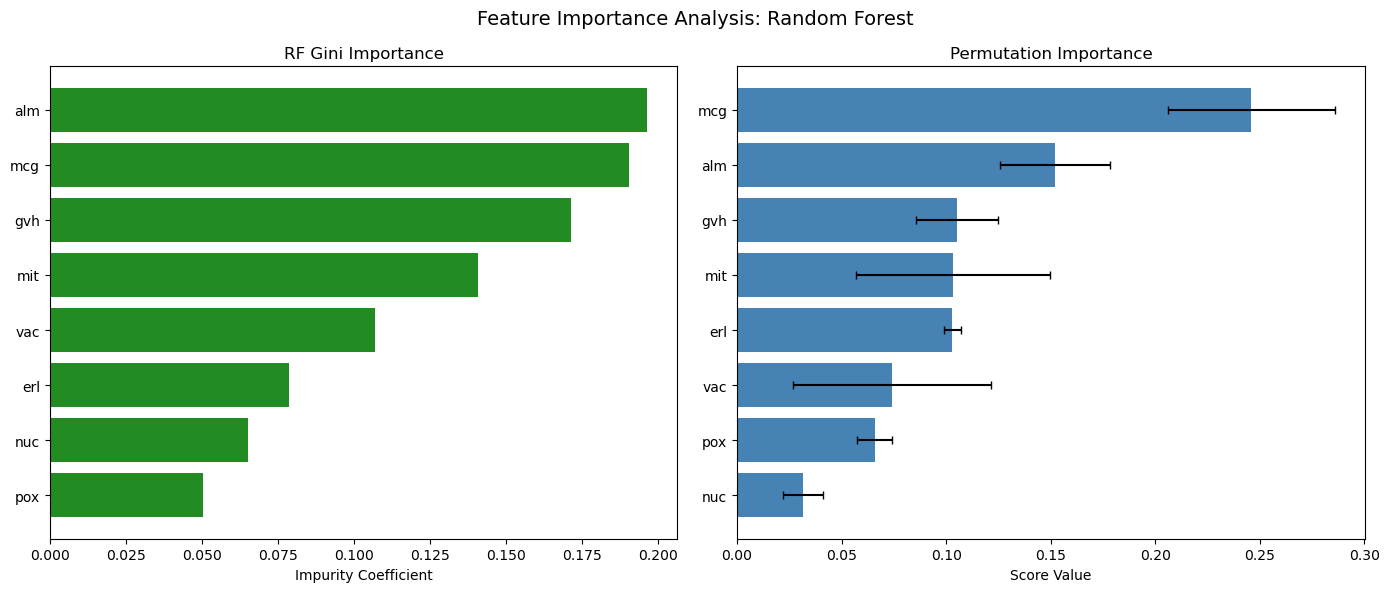

In [21]:

from sklearn.inspection import permutation_importance

#get classifier rf
rf_model = results['Random Forest']['model'] 
rf_classifier = rf_model.named_steps['clf'] 

# gini
rf_importance = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': rf_classifier.feature_importances_
}).sort_values('Importance')

perm_importance = permutation_importance(
    rf_model, X_test, y_test, 
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
    scoring='f1_macro' 
)

perm_importance_df = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
}).sort_values('Importance', ascending=False)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gini Importance
rf_importance_sorted = rf_importance.sort_values('Importance')
axes[0].barh(rf_importance_sorted['Feature'], rf_importance_sorted['Importance'], color='forestgreen')
axes[0].set_title('RF Gini Importance')
axes[0].set_xlabel('Impurity Coefficient')

# Permutation Importance
perm_sorted = perm_importance_df.sort_values('Importance')
axes[1].barh(perm_sorted['Feature'], perm_sorted['Importance'], 
             xerr=perm_sorted['Std'], color='steelblue', capsize=3)
axes[1].set_title('Permutation Importance')
axes[1].set_xlabel('Score Value')

plt.suptitle('Feature Importance Analysis: Random Forest', fontsize=14)
plt.tight_layout()
plt.show()


- `alm` and `mcg` are the top two features under both measures, so the model relies on transmembrane and signal-peptide information.
- `nuc` ranks at or near the bottom in both measures, even though NUC is the second-largest class. The nuclear localisation score adds little discriminative power, which helps explain the CYT/NUC confusion.
- `erl` ranks noticeably higher permutation than under Gini. Gini importance tends to undervalue low-cardinality features, but `erl` matters on test data because it identifies ERL.

## 8. Predictions on unlabelled proteins
The Random Forest trained on 80% of the data is used as-is rather than retrained on 100%. This way the test-set metrics above describe exactly the model making these predictions. With ~1,170 training proteins, the small gain from 20% more data does not outweigh having a verifiable performance estimate. Confidence is the highest predicted class probability.

In [ ]:
X_unlabelled = df_unlabelled[FEATURES]
predictions_encoded = best_model.predict(X_unlabelled)
predictions = le.inverse_transform(predictions_encoded)


if hasattr(best_model, 'predict_proba'):
    probabilities = best_model.predict_proba(X_unlabelled)
    confidence = np.max(probabilities, axis=1)
else:
    confidence = np.ones(len(predictions))  


predictions_df = pd.DataFrame({
    'Protein no.': range(1, len(predictions) + 1),
    'Predicted_Localisation': predictions,
    'Confidence': confidence
})


for i, cls in enumerate(class_labels):  # class_labels follows the LabelEncoder order, matching predict_proba columns
    if hasattr(best_model, 'predict_proba'):
        predictions_df[f'Prob_{cls}'] = probabilities[:, i]

print(predictions_df[['Protein no.', 'Predicted_Localisation', 'Confidence']].to_string(index=False))
print(predictions_df['Predicted_Localisation'].value_counts())

 Protein no. Predicted_Localisation  Confidence
           1                    ME3    0.800355
           2                    CYT    0.391001
           3                    NUC    0.476500
           4                    CYT    0.487670
           5                    NUC    0.433233
           6                    NUC    0.621265
           7                    CYT    0.579115
           8                    EXC    0.426423
           9                    MIT    0.786360
          10                    ME2    0.251965
          11                    CYT    0.679014
          12                    ME3    0.386709
          13                    MIT    0.643401
          14                    CYT    0.514055
          15                    MIT    0.904058
          16                    NUC    0.602874
          17                    NUC    0.435407
          18                    MIT    0.418175
          19                    ME1    0.492185
          20                    CYT    0

- The predicted mix (6 CYT, 5 NUC, 4 MIT, 2 ME3, 1 each of EXC, ME2, ME1) mirrors the class balance of the training data.
- The highest-confidence calls are protein 15 (MIT, 0.90), protein 1 (ME3, 0.80) and protein 9 (MIT, 0.79), all classes with distinctive features.
- Most CYT and NUC predictions have confidence below 0.6, consistent with the overlap between these two classes. Protein 10 (ME2, 0.25) is the least certain call.

## 9. Summary
- Five classifiers were tuned with stratified 5-fold CV on macro-F1 to handle a 10-class, heavily imbalanced dataset.
- **Random Forest** was selected: test macro-F1 0.595, weighted-F1 0.583, accuracy 0.594.
- Signal-peptide (`mcg`) and transmembrane (`alm`) scores carry most of the predictive signal. The main remaining limitation is separating cytosolic from nuclear proteins, whose features largely overlap.

## 10. Next steps
- Implement SMOTE to oversample rare classes, to further correct for the heavy imbalance. 
- A dedicated model may better separate classes CYT and NUC. 